# RGB + Thermal AI for Rheumatoid Arthritis

In [1]:
%pip install -q mediapipe   # Kaggle: Settings > Internet must be ON. Restart the kernel if numpy/protobuf complain.

Note: you may need to restart the kernel to use updated packages.


## Setup

Loads the libraries, finds the FLIR dataset and sets the main settings. Run this first.

In [2]:
# pip install numpy opencv-python matplotlib mediapipe torch torchvision scikit-learn onnx
import glob, os, random, time
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Dataset: Kaggle finds it automatically. Locally set ROOT = Path("path/to/FLIROne")
found = glob.glob("/kaggle/input/**/FLIROne", recursive=True)
ROOT = Path(found[0]) if found else Path("FLIROne")
SUBJECTS = sorted(p.name for p in ROOT.iterdir() if p.is_dir())

# Settings
SUBJ, HAND, TASK = "S1", "right", "static"    # recording used by the demo cells
ROI_SIZE, N_ROIS = 96, 8                       # 8 joint crops (4 MCP + 4 PIP), 96x96 pixels each
ORIENT = "as is"                               # thermal orientation, verified in Stage 03
MIN_OVERLAP = 0.5                              # gate: share of the landmark hull that must be warm (0 = off)
TARGET_F1, TARGET_AUROC = 0.7772, 0.90         # project targets (RA vs non-RA)

bgr2rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
print(f"torch {torch.__version__} | device {DEVICE} | {len(SUBJECTS)} subjects")

torch 2.11.0+cu130 | device cuda | 17 subjects


## Stage 01: Capture paired images

**What it does:** reads the RGB video and the thermal temperature file together, frame by frame. The RGB has black side bars, so they are cropped off and both images end up the same size.

**What to check:** RGB and thermal show the same hand facing the same way, and the temperature curve jumps when the hand enters the view.

In [3]:
ORIENTS = {                                     # ways the thermal array could be turned (same shape)
    "as is":  lambda a: a,
    "rot180": lambda a: np.rot90(a, 2),
    "flipud": lambda a: a[::-1],
    "fliplr": lambda a: a[:, ::-1],
}

def load_recording(subject, hand, task):
    folder = ROOT / subject / f"{hand} hand"
    cap = cv2.VideoCapture(str(folder / f"{task}_RGB.mp4"))
    seq = np.load(folder / f"{task}_Thermal_Radiometric_Sequence.npy", mmap_mode="r")   # (frames, 640, 480) deg C
    return cap, seq

def thermal_frame(seq, i):
    t = np.asarray(seq[i], dtype=np.float32)
    return np.ascontiguousarray(ORIENTS[ORIENT](t))

def rgb_content_box(frame, thr=8):
    # the RGB video is a portrait picture padded with black side bars: find the real picture area
    g = frame.max(axis=2).astype(np.float32)
    cols, rows = np.where(g.mean(axis=0) > thr)[0], np.where(g.mean(axis=1) > thr)[0]
    if len(cols) == 0 or len(rows) == 0:
        return 0, frame.shape[1], 0, frame.shape[0]
    return cols[0], cols[-1] + 1, rows[0], rows[-1] + 1

def iter_pairs(subject, hand, task, step=10):
    # yields (frame index, RGB, thermal deg C); both are 640x480 portrait and show the same view
    cap, seq = load_recording(subject, hand, task)
    box, i = None, 0
    try:
        while i < seq.shape[0]:
            ok, frame = cap.read()               # read in order so frame i matches seq[i]
            if not ok:
                break
            box = box or rgb_content_box(frame)
            if i % step == 0:
                x0, x1, y0, y1 = box
                thermal = thermal_frame(seq, i)
                rgb = cv2.resize(frame[y0:y1, x0:x1], (thermal.shape[1], thermal.shape[0]))
                yield i, rgb, thermal
            i += 1
    finally:
        cap.release()

30 frames | RGB (640, 480, 3) | thermal (640, 480) | 22.8 to 33.8 deg C


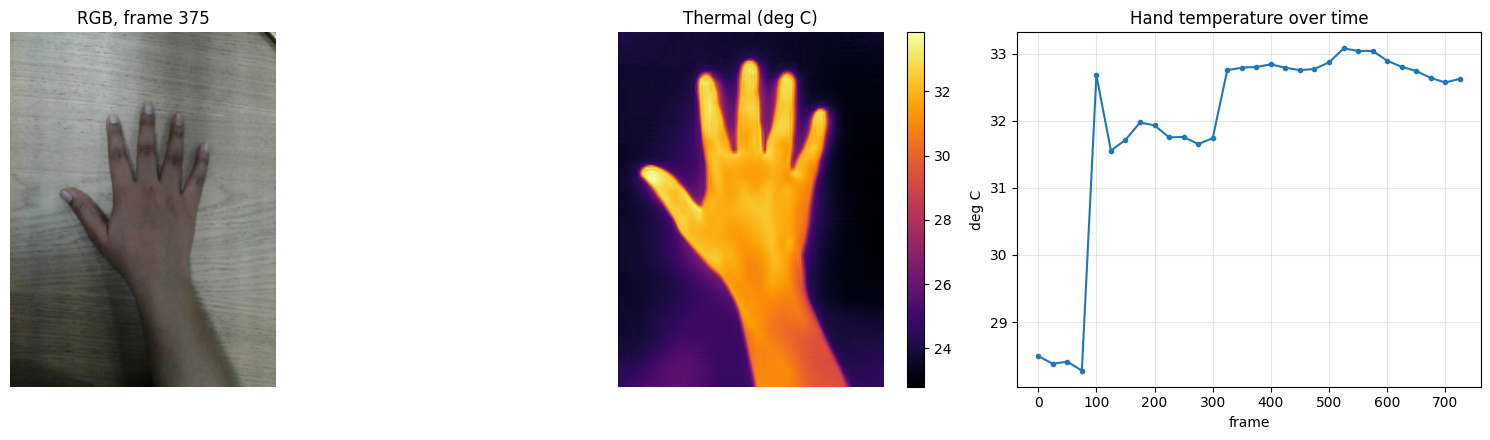

In [4]:
pairs = list(iter_pairs(SUBJ, HAND, TASK, step=25))
idx, rgb0, th0 = pairs[len(pairs) // 2]
print(f"{len(pairs)} frames | RGB {rgb0.shape} | thermal {th0.shape} | {th0.min():.1f} to {th0.max():.1f} deg C")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].imshow(bgr2rgb(rgb0)); ax[0].set_title(f"RGB, frame {idx}"); ax[0].axis("off")
im = ax[1].imshow(th0, cmap="inferno"); ax[1].set_title("Thermal (deg C)"); ax[1].axis("off")
plt.colorbar(im, ax=ax[1], fraction=0.046)
ax[2].plot([p[0] for p in pairs], [np.percentile(p[2], 99) for p in pairs], marker="o", ms=3)
ax[2].set(title="Hand temperature over time", xlabel="frame", ylabel="deg C"); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

## Stage 02: Image quality check

**What it does:** rejects bad frames before the AI sees them: blurry, badly lit, or no hand in view. The blur limit is set per recording (its blurriest 25% are dropped).

**What to check:** in the sharpness plot, frames below the dashed line are rejected.

In [5]:
def quality_check(rgb, thermal, min_sharp=None, bright=(40, 220), min_thermal_range=4.0, min_hand_temp=29.5):
    gray = cv2.cvtColor(rgb, cv2.COLOR_BGR2GRAY)
    sharp = cv2.Laplacian(gray, cv2.CV_64F).var()
    p1, p99 = np.percentile(thermal, [1, 99])
    reasons = []
    if min_sharp is not None and sharp < min_sharp:      reasons.append("blurry")
    if not bright[0] <= gray.mean() <= bright[1]:        reasons.append("bad lighting")
    if p99 - p1 < min_thermal_range or p99 < min_hand_temp:
        reasons.append("low thermal contrast / no hand")
    return {"ok": not reasons, "reasons": reasons, "sharpness": sharp}

def calibrate_min_sharp(sharpness_values, pct=25):
    # blur gate set per recording: drop its blurriest `pct` percent (sharpness depends on camera and scene)
    return float(np.percentile(sharpness_values, pct))

static     min_sharp  24.2 | pass 63% | rejected: {'blurry': 8, 'low thermal contrast / no hand': 4}
open_close min_sharp  32.8 | pass 75% | rejected: {'blurry': 7}


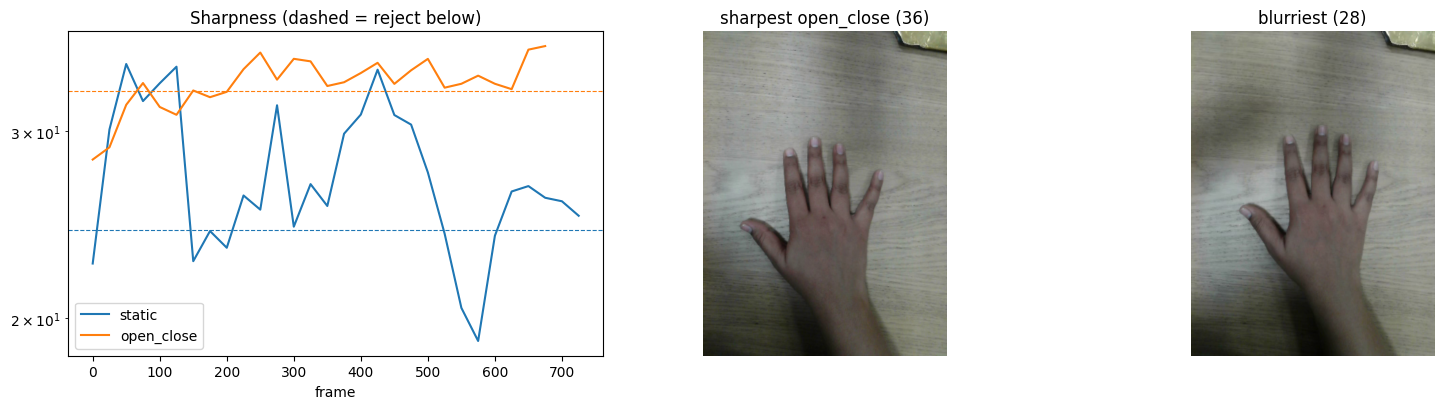

In [6]:
pairs_oc = list(iter_pairs(SUBJ, HAND, "open_close", step=25))

def run_quality(frames):
    sharp = [quality_check(r, t)["sharpness"] for _, r, t in frames]
    thr = calibrate_min_sharp(sharp)
    return sharp, thr, [quality_check(r, t, min_sharp=thr) for _, r, t in frames]

sh_s, thr_s, q_s = run_quality(pairs)
sh_o, thr_o, q_o = run_quality(pairs_oc)
for name, q, thr in (("static", q_s, thr_s), ("open_close", q_o, thr_o)):
    print(f"{name:10s} min_sharp {thr:5.1f} | pass {np.mean([x['ok'] for x in q]):.0%} | "
          f"rejected: {dict(Counter(r for x in q for r in x['reasons']))}")

best, worst = int(np.argmax(sh_o)), int(np.argmin(sh_o))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot([p[0] for p in pairs], sh_s, label="static"); ax[0].plot([p[0] for p in pairs_oc], sh_o, label="open_close")
ax[0].axhline(thr_s, color="C0", ls="--", lw=.8); ax[0].axhline(thr_o, color="C1", ls="--", lw=.8)
ax[0].set(title="Sharpness (dashed = reject below)", xlabel="frame", yscale="log"); ax[0].legend()
ax[1].imshow(bgr2rgb(pairs_oc[best][1])); ax[1].set_title(f"sharpest open_close ({sh_o[best]:.0f})"); ax[1].axis("off")
ax[2].imshow(bgr2rgb(pairs_oc[worst][1])); ax[2].set_title(f"blurriest ({sh_o[worst]:.0f})"); ax[2].axis("off")
plt.tight_layout(); plt.show()

## Hand detector (used by Stages 03 and 04)

**What it does:** MediaPipe finds 21 points on the hand. A second check rejects frames where the hand is cut off, the points are uncertain, or the hand does not match the thermal image.

In [7]:
import mediapipe as mp

MODEL_URL = ("https://storage.googleapis.com/mediapipe-models/hand_landmarker/"
             "hand_landmarker/float16/latest/hand_landmarker.task")
MODEL_PATH = "hand_landmarker.task"
MCP, PIP = [5, 9, 13, 17], [6, 10, 14, 18]
JOINTS = MCP + PIP
JOINT_NAMES = [f"{k} {f}" for k in ("MCP", "PIP") for f in ("index", "middle", "ring", "little")]
_detector = None

def _get_detector():
    global _detector
    if _detector is None:
        if hasattr(mp, "solutions"):                                  # older MediaPipe
            _detector = ("legacy", mp.solutions.hands.Hands(static_image_mode=True, max_num_hands=1,
                                                            min_detection_confidence=0.5))
        else:                                                         # newer MediaPipe (Tasks API)
            import urllib.request
            from mediapipe.tasks import python as mp_python
            from mediapipe.tasks.python import vision
            if not os.path.exists(MODEL_PATH):
                urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)
            opts = vision.HandLandmarkerOptions(base_options=mp_python.BaseOptions(model_asset_path=MODEL_PATH),
                                                num_hands=1, min_hand_detection_confidence=0.5)
            _detector = ("tasks", vision.HandLandmarker.create_from_options(opts))
    return _detector

def detect_hand(bgr):
    # returns (21 landmarks in pixels, confidence) or None
    kind, det = _get_detector()
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    h, w = rgb.shape[:2]
    if kind == "legacy":
        res = det.process(rgb)
        if not res.multi_hand_landmarks:
            return None
        lm, score = res.multi_hand_landmarks[0].landmark, res.multi_handedness[0].classification[0].score
    else:
        res = det.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb)))
        if not res.hand_landmarks:
            return None
        lm, score = res.hand_landmarks[0], res.handedness[0][0].score
    return np.array([[p.x * w, p.y * h] for p in lm], dtype=np.float32), float(score)

def hot_mask(thermal):
    # hand-vs-background mask from the thermal image (Otsu threshold)
    t8 = cv2.normalize(thermal, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    return cv2.threshold(t8, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]

def hand_overlap(pts, thermal):
    # share of the RGB landmark hull that is warm in thermal (low = misaligned, glove, or occlusion)
    hull = np.zeros(thermal.shape, np.uint8)
    cv2.fillConvexPoly(hull, cv2.convexHull(pts.astype(np.int32)), 1)
    return float((hot_mask(thermal) & hull).sum() / max(hull.sum(), 1))

def reliability_gate(q, det, thermal, min_score=0.8, min_overlap=None):
    # second part of the quality gate: is the hand found, fully visible, and matching the thermal image?
    min_overlap = MIN_OVERLAP if min_overlap is None else min_overlap
    reasons = list(q["reasons"])
    if det is None:
        return False, reasons + ["no hand detected"]
    pts, score = det
    h, w = thermal.shape
    if score < min_score:
        reasons.append("uncertain landmarks")
    if pts[:, 0].min() < 0 or pts[:, 1].min() < 0 or pts[:, 0].max() >= w or pts[:, 1].max() >= h:
        reasons.append("hand cut off by frame")
    if min_overlap > 0 and hand_overlap(pts, thermal) < min_overlap:
        reasons.append("RGB-thermal mismatch")
    return len(reasons) == 0, reasons

I0000 00:00:1795399284.399416     915 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Stage 03: Align and preprocess

**What it does:** (1) checks the thermal image is the right way up, (2) lines thermal up with RGB using one scale-and-shift fitted from matching hand points, (3) fixes brightness with gamma correction, (4) removes thermal noise with a small denoising network.

**What to check:** after alignment the green outline should hug the hand, and the denoiser's RMSE should be lower than the noisy input's.

In [8]:
def gamma_correct(rgb, target=110):
    # moves the mean brightness towards `target` (does nothing if the frame is already there)
    mean = float(np.clip(cv2.cvtColor(rgb, cv2.COLOR_BGR2GRAY).mean() / 255.0, 0.02, 0.98))
    gamma = float(np.clip(np.log(target / 255.0) / np.log(mean), 0.5, 2.0))
    lut = (np.linspace(0, 1, 256) ** gamma * 255).astype(np.uint8)
    return cv2.LUT(rgb, lut)

def thermal_pseudo_bgr(t):
    # thermal (deg C) -> colour picture, so the same hand detector works on thermal
    lo, hi = np.percentile(t, [1, 99.5])
    t8 = (np.clip((t - lo) / max(hi - lo, 1e-3), 0, 1) * 255).astype(np.uint8)
    return cv2.applyColorMap(t8, cv2.COLORMAP_INFERNO)

def landmark_pairs(frames, max_frames=24):
    # matching hand landmarks (thermal points A, RGB points B) from up to max_frames frame pairs
    A, B, hand_len = [], [], []
    for k in np.unique(np.linspace(0, len(frames) - 1, min(max_frames, len(frames))).astype(int)):
        _, rgb, th = frames[k]
        d_rgb, d_th = detect_hand(rgb), detect_hand(thermal_pseudo_bgr(th))
        if d_rgb is None or d_th is None:
            continue
        A.append(d_th[0]); B.append(d_rgb[0]); hand_len.append(np.linalg.norm(d_rgb[0][0] - d_rgb[0][9]))
    if len(A) < 3:
        return None
    return np.concatenate(A).astype(np.float32), np.concatenate(B).astype(np.float32), float(np.median(hand_len))

def calibrate_registration(frames, verbose=True):
    # fit ONE thermal->RGB transform (scale, small rotation, shift) from matching landmarks
    got = landmark_pairs(frames)
    if got is None:
        verbose and print("registration: hand not found in enough frames -> thermal left unregistered")
        return None, {}
    A, B, hand_len = got
    M, inl = cv2.estimateAffinePartial2D(A, B, method=cv2.RANSAC, ransacReprojThreshold=6.0)
    if M is None:
        verbose and print("registration: fit failed -> thermal left unregistered")
        return None, {}
    scale, rot = float(np.hypot(M[0, 0], M[1, 0])), float(np.degrees(np.arctan2(M[1, 0], M[0, 0])))
    err_before = float(np.median(np.linalg.norm(A - B, axis=1)))
    err_after = float(np.median(np.linalg.norm(A @ M[:, :2].T + M[:, 2] - B, axis=1)))
    info = dict(scale=scale, rot_deg=rot, err_before=err_before, err_after=err_after, hand_len=hand_len)
    if err_after > 0.08 * hand_len or not 0.5 < scale < 1.5 or abs(rot) > 15:    # refuse a bad fit
        verbose and print(f"registration rejected: error {100 * err_after / hand_len:.0f}% of hand, scale {scale:.2f}, rot {rot:.0f} deg")
        return None, info
    if verbose:
        print(f"registration: scale {scale:.3f} | rot {rot:.1f} deg | shift ({M[0, 2]:.0f}, {M[1, 2]:.0f}) px | "
              f"landmark error {100 * err_before / hand_len:.0f}% -> {100 * err_after / hand_len:.0f}% of hand length")
    return M, info

def register_thermal(thermal, M, shape_hw):
    # warp thermal onto the RGB pixel grid (M = None: leave unchanged)
    if M is None:
        return thermal
    h, w = shape_hw
    return cv2.warpAffine(np.ascontiguousarray(thermal, dtype=np.float32), M, (w, h),
                          flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)

def preprocess_pair(rgb, thermal, M):
    # the one preprocessing path used for training, evaluation and the demo
    return gamma_correct(rgb), register_thermal(thermal, M, rgb.shape[:2])

def mismatch_pct(A, B, hand_len):
    # landmark error (% of hand length) after the best scale + shift. No rotation is allowed here, so a
    # thermal image that is upside-down cannot be "fixed" by the fit and scores badly.
    a, b = A - A.mean(0), B - B.mean(0)
    s = max(float((a * b).sum() / max((a * a).sum(), 1e-9)), 0.1)      # scale must stay positive (negative = turned 180 deg)
    t = B.mean(0) - s * A.mean(0)
    return 100 * float(np.median(np.linalg.norm(s * A + t - B, axis=1))) / hand_len

def orientation_check(subject, hand, task, n=8):
    # for each way of turning the thermal array, how well do its hand landmarks match the RGB ones?
    cap, seq = load_recording(subject, hand, task)
    want = set(np.linspace(seq.shape[0] // 3, seq.shape[0] - 1, n).astype(int).tolist())
    box, raws, i = None, [], 0
    while i < seq.shape[0]:
        ok, f = cap.read()
        if not ok:
            break
        box = box or rgb_content_box(f)
        if i in want:
            raws.append((f[box[2]:box[3], box[0]:box[1]], np.asarray(seq[i], dtype=np.float32)))
        i += 1
    cap.release()
    result = {}
    for name, fn in ORIENTS.items():
        frames = []
        for f, raw in raws:
            th = np.ascontiguousarray(fn(raw))
            frames.append((0, cv2.resize(f, (th.shape[1], th.shape[0])), th))
        got = landmark_pairs(frames, max_frames=n)
        result[name] = None if got is None else mismatch_pct(*got)
    return result

INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x7bc63c003cd0, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
INFO: [environment.cc:36] Creating LiteRT environment with options
INFO: [accelerator_registry.cc:54] RegisterAccelerator: ptr=0x7bc6400037b0, name=CpuAccelerator
INFO: [cpu_registry.cc:75] XNNPACK CPU accelerator registered.
INFO: [compiled_model.cc:1022] Flatbuffer model initialized directly from incoming litert model.
W0000 00:00:1795399286.818270    1029 inference_runner_litert.cc:1433] Input tensor memory is not aligned according to LiteRt's memory alignment requirements. Reallocating memory and copying data.
W0000 00:00:1795399286.862076    1026 landmark_projection_calculator.cc:81] Using NORM_RECT without I

orientation check (landmark error, % of hand length; lower is better):
   as is     2.0%
   flipud   60.9%
   fliplr   65.4%
   rot180   67.9%
best: 'as is' | ORIENT in use: 'as is'
registration: scale 0.824 | rot 0.8 deg | shift (54, 81) px | landmark error 30% -> 3% of hand length


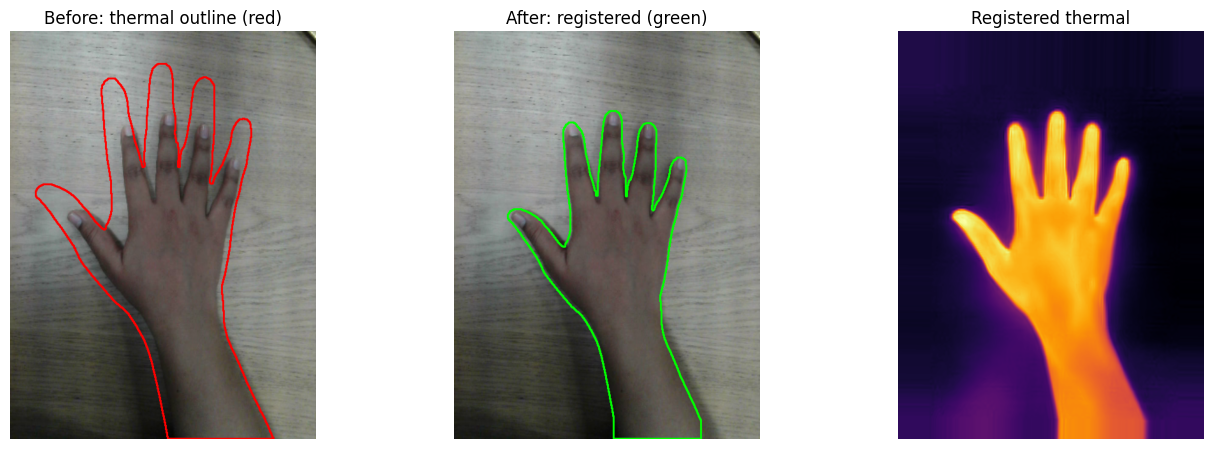

gamma: mean brightness 49 -> 107 (target 110)


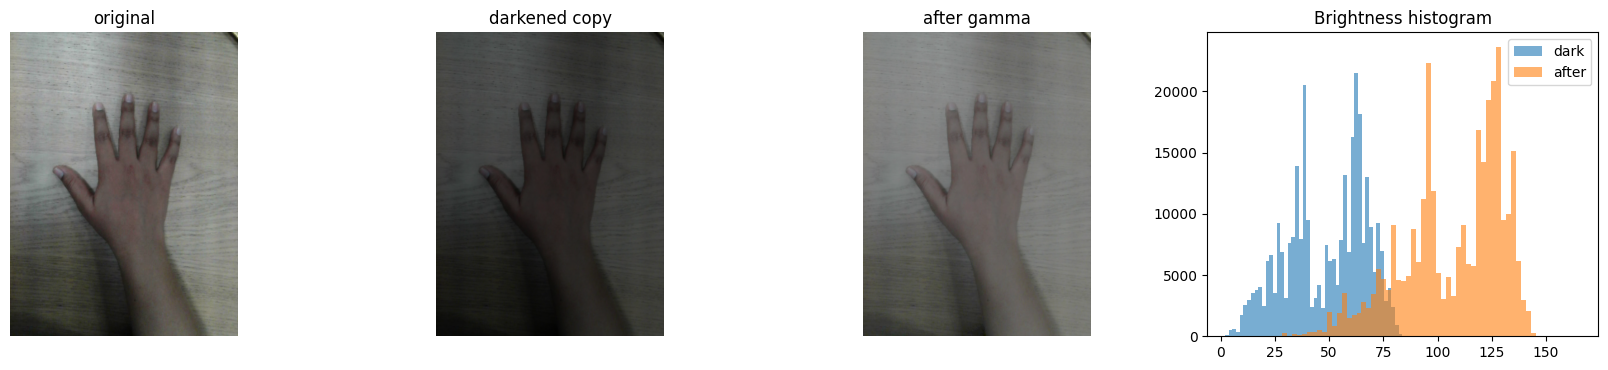

In [9]:
# 1) is the thermal array the right way up?
orient = orientation_check(SUBJ, HAND, TASK)
print("orientation check (landmark error, % of hand length; lower is better):")
for name, v in sorted(orient.items(), key=lambda kv: (kv[1] is None, kv[1] or 0)):
    print(f"   {name:7s} " + (f"{v:5.1f}%" if v is not None else "hand not found"))
valid = {k: v for k, v in orient.items() if v is not None}
if valid:
    print(f"best: {min(valid, key=valid.get)!r} | ORIENT in use: {ORIENT!r}")

# 2) registration: one transform maps thermal onto the RGB picture
M0, reg = calibrate_registration(pairs + pairs_oc)
th0r = register_thermal(th0, M0, rgb0.shape[:2])
outline = lambda im, th, col: cv2.drawContours(im, cv2.findContours(hot_mask(th), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0], -1, col, 2)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.6))
ax[0].imshow(bgr2rgb(outline(rgb0.copy(), th0, (0, 0, 255)))); ax[0].set_title("Before: thermal outline (red)")
ax[1].imshow(bgr2rgb(outline(rgb0.copy(), th0r, (0, 255, 0)))); ax[1].set_title("After: registered (green)")
ax[2].imshow(th0r, cmap="inferno"); ax[2].set_title("Registered thermal")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# 3) gamma correction, tested on a darkened copy
dark = (rgb0 * 0.45).astype(np.uint8); fixed = gamma_correct(dark)
gray = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
print(f"gamma: mean brightness {gray(dark).mean():.0f} -> {gray(fixed).mean():.0f} (target 110)")
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, im, t in zip(ax, (rgb0, dark, fixed), ("original", "darkened copy", "after gamma")):
    a.imshow(bgr2rgb(im)); a.set_title(t); a.axis("off")
ax[3].hist(gray(dark).ravel(), 64, alpha=.6, label="dark"); ax[3].hist(gray(fixed).ravel(), 64, alpha=.6, label="after")
ax[3].legend(); ax[3].set_title("Brightness histogram")
plt.tight_layout(); plt.show()

In [10]:
class ThermalDAE(nn.Module):
    # residual denoiser: predicts the noise and subtracts it (starts as the identity)
    def __init__(self, ch=16):
        super().__init__()
        kw = dict(padding=1, padding_mode="replicate")
        self.body = nn.Sequential(nn.Conv2d(1, ch, 3, **kw), nn.ReLU(), nn.Conv2d(ch, ch, 3, **kw), nn.ReLU(),
                                  nn.Conv2d(ch, 1, 3, **kw))
        nn.init.zeros_(self.body[-1].weight); nn.init.zeros_(self.body[-1].bias)
    def forward(self, x):
        return x - self.body(x)

def train_dae(dae, clean_batches, epochs=60, noise_std=0.02, lr=2e-3, crop=160):
    # clean_batches: (B,1,H,W) tensors, temperature scaled as (T - 15) / 25. Trains on random crops.
    opt = torch.optim.Adam(dae.parameters(), lr=lr)
    dae.to(DEVICE).train()
    losses = []
    for _ in range(epochs):
        for clean in clean_batches:
            H, W = clean.shape[2:]
            y0, x0 = np.random.randint(0, H - crop + 1), np.random.randint(0, W - crop + 1)
            c = clean[:, :, y0:y0 + crop, x0:x0 + crop].to(DEVICE)
            loss = F.mse_loss(dae(c + noise_std * torch.randn_like(c)), c)
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
    return losses

def classical_denoise(t):
    t = np.ascontiguousarray(t, dtype=np.float32)
    return {"gaussian": cv2.GaussianBlur(t, (5, 5), 1.0), "bilateral": cv2.bilateralFilter(t, 5, 0.3, 3)}

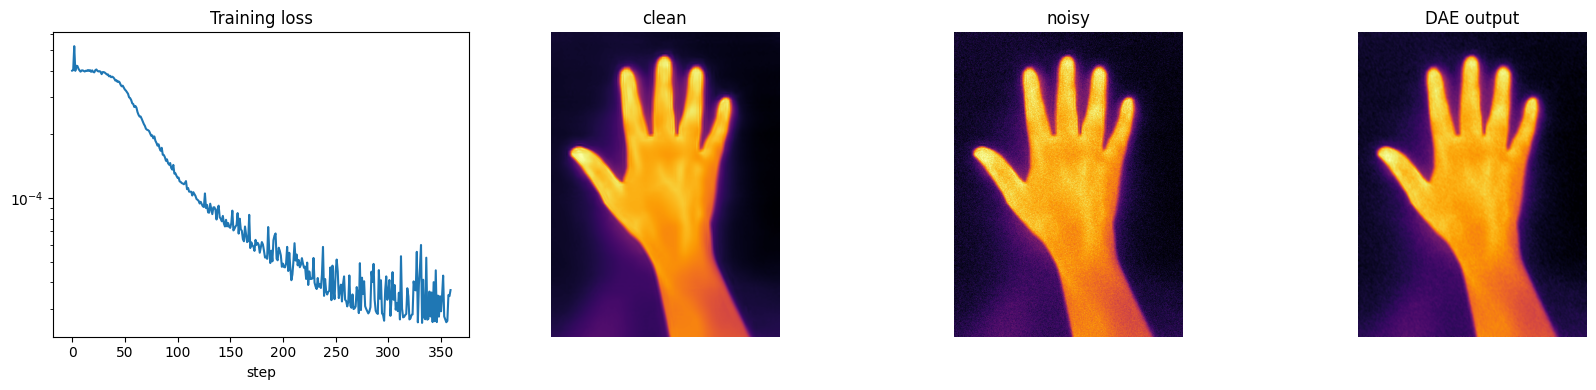

RMSE vs clean (deg C): noisy 0.500 | DAE 0.125 | gaussian 0.148 | bilateral 0.424


In [11]:
# denoiser test: clean target = mean of 8 frames of the static recording; noise is added artificially
cap, seq = load_recording(SUBJ, HAND, "static"); cap.release()
starts = list(range(100, seq.shape[0] - 8, 40))[:12]                  # skip the first frames (no hand yet)
means = [np.stack([thermal_frame(seq, s + k) for k in range(8)]).mean(0) for s in starts]
to_t = lambda a: torch.from_numpy(((a - 15.0) / 25.0).astype(np.float32))[None, None]
hold = means.pop()                                                    # held-out frame, never trained on
batches = [torch.cat([to_t(m) for m in means[i:i + 2]]) for i in range(0, len(means), 2)]

NOISE = 0.02                                                          # 0.02 * 25 = 0.5 deg C
dae = ThermalDAE()
dae_losses = train_dae(dae, batches, noise_std=NOISE)
dae.eval()
x = to_t(hold).to(DEVICE)
noisy = x + NOISE * torch.randn(x.shape, generator=torch.Generator().manual_seed(0)).to(DEVICE)
with torch.no_grad():
    den = dae(noisy)
to_c = lambda t: t[0, 0].cpu().numpy() * 25.0 + 15.0
rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
clean_c, noisy_c, den_c = to_c(x), to_c(noisy), to_c(den)
classic = classical_denoise(noisy_c)

fig, ax = plt.subplots(1, 4, figsize=(17, 4))
ax[0].plot(dae_losses); ax[0].set(title="Training loss", xlabel="step", yscale="log")
for a, im, t in zip(ax[1:], (clean_c, noisy_c, den_c), ("clean", "noisy", "DAE output")):
    a.imshow(im, cmap="inferno", vmin=clean_c.min(), vmax=clean_c.max()); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()
print(f"RMSE vs clean (deg C): noisy {rmse(noisy_c, clean_c):.3f} | DAE {rmse(den_c, clean_c):.3f} | "
      f"gaussian {rmse(classic['gaussian'], clean_c):.3f} | bilateral {rmse(classic['bilateral'], clean_c):.3f}")

## Stage 04: Detect hand and joints

**What it does:** cuts a small square around each of 8 finger joints (4 MCP and 4 PIP), where RA usually appears.

**What to check:** the boxes sit on the knuckles and finger joints, and the thermal crops show the same joints as the RGB crops.

In [12]:
def roi_half(pts, scale=0.35):
    # half the crop side: a fraction of the wrist-to-middle-finger-base distance
    return max(int(scale * np.linalg.norm(pts[0] - pts[9]) / 2), 8)

def crop_rois(img, pts, size=ROI_SIZE):
    # one square crop per joint (image is edge-padded, so joints near the border still give full squares)
    half = roi_half(pts)
    padded = cv2.copyMakeBorder(img, half, half, half, half, cv2.BORDER_REPLICATE)
    h, w = img.shape[:2]
    out = []
    for j in JOINTS:
        cx, cy = int(np.clip(pts[j][0], 0, w - 1)), int(np.clip(pts[j][1], 0, h - 1))
        out.append(cv2.resize(padded[cy:cy + 2 * half, cx:cx + 2 * half], (size, size)))
    return np.stack(out)                                   # (8, 96, 96[, channels])

landmark confidence 0.94 | hand overlap 0.77 | gate: PASS


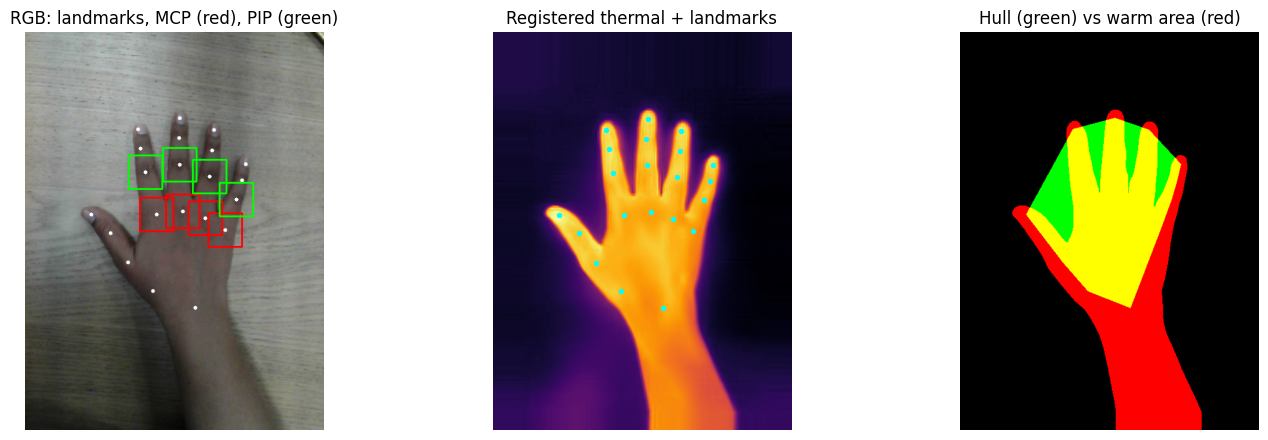

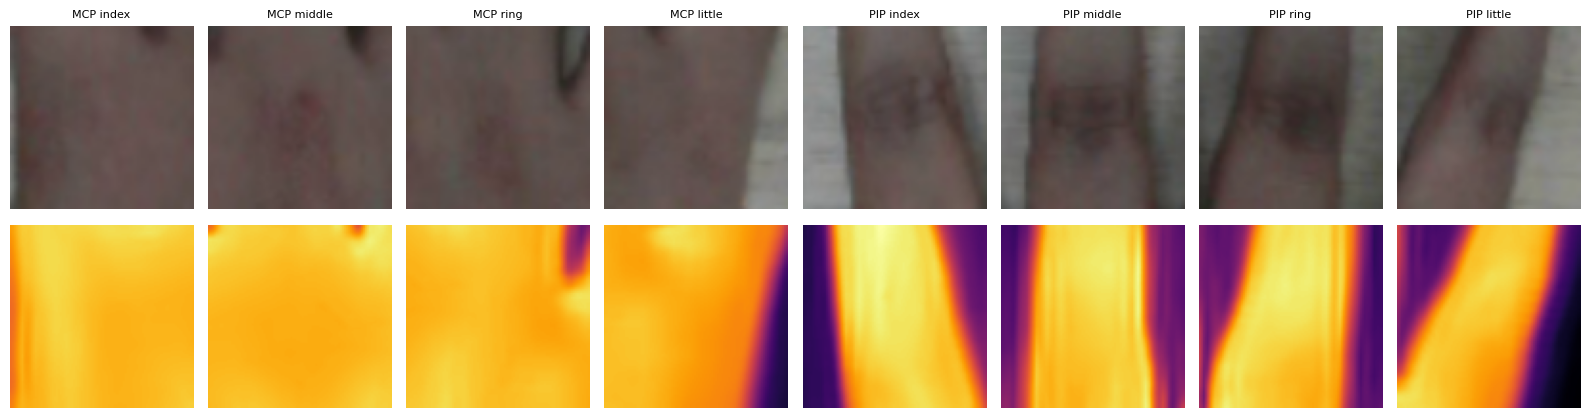

In [13]:
rgb0g = gamma_correct(rgb0)
det = detect_hand(rgb0g)
assert det is not None, "No hand found: change SUBJ / HAND in Setup."
pts, score = det
ok, why = reliability_gate(quality_check(rgb0, th0), det, th0r)
print(f"landmark confidence {score:.2f} | hand overlap {hand_overlap(pts, th0r):.2f} | gate: {'PASS' if ok else 'REJECT ' + str(why)}")

P = lambda p: (int(p[0]), int(p[1]))
vis, half = rgb0g.copy(), roi_half(pts)
for p in pts:
    cv2.circle(vis, P(p), 3, (255, 255, 255), -1)
for j in JOINTS:
    x, y = P(pts[j])
    cv2.rectangle(vis, (x - half, y - half), (x + half, y + half), (0, 0, 255) if j in MCP else (0, 255, 0), 2)
hull = np.zeros(th0r.shape, np.uint8); cv2.fillConvexPoly(hull, cv2.convexHull(pts.astype(np.int32)), 1)
overlap_img = np.stack([hot_mask(th0r) * 255, hull * 255, np.zeros_like(hull)], -1)      # red = warm, green = hull

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
ax[0].imshow(bgr2rgb(vis)); ax[0].set_title("RGB: landmarks, MCP (red), PIP (green)")
ax[1].imshow(th0r, cmap="inferno"); ax[1].scatter(pts[:, 0], pts[:, 1], c="cyan", s=8); ax[1].set_title("Registered thermal + landmarks")
ax[2].imshow(overlap_img); ax[2].set_title("Hull (green) vs warm area (red)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

rgb_rois, th_rois = crop_rois(rgb0g, pts), crop_rois(th0r, pts)
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for k in range(8):
    ax[0, k].imshow(bgr2rgb(rgb_rois[k])); ax[0, k].set_title(JOINT_NAMES[k], fontsize=8)
    ax[1, k].imshow(th_rois[k], cmap="inferno", vmin=th_rois.min(), vmax=th_rois.max())
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.tight_layout(); plt.show()

## Stage 05: Feature extraction (two MobileNetV3-Small branches)

**What it does:** two small MobileNetV3-Small networks turn the crops into numbers, one for RGB and one for thermal. The thermal one also receives how much warmer each joint is than the palm (joint-minus-palm temperature).

**What to check:** the bar chart of joint temperatures against the palm, and about 0.93M parameters per network.

In [14]:
IMNET_MEAN = np.float32([0.406, 0.456, 0.485])             # ImageNet statistics, BGR order
IMNET_STD = np.float32([0.225, 0.224, 0.229])

def rgb_rois_to_tensor(rgb_bgr, pts):
    r = (crop_rois(rgb_bgr, pts).astype(np.float32) / 255.0 - IMNET_MEAN) / IMNET_STD
    return torch.from_numpy(r).permute(0, 3, 1, 2)         # (8, 3, 96, 96)

def thermal_rois_numpy(thermal, pts):
    # thermal must already be registered to the RGB picture. Returns 2-channel crops and per-joint delta-T.
    poly = np.zeros(thermal.shape, np.uint8)
    cv2.fillConvexPoly(poly, pts[[0, 5, 9, 13, 17]].astype(np.int32), 1)          # palm polygon
    vals = thermal[poly > 0]
    t_ref = float(np.median(vals)) if vals.size else float(np.median(thermal))    # palm reference temperature

    # hand mask: halfway between palm and background, so background never enters the crops or delta-T
    thr = min(0.5 * (t_ref + float(np.percentile(thermal, 5))), t_ref - 3.0)
    mask = cv2.erode((thermal > thr).astype(np.uint8), np.ones((5, 5), np.uint8))
    rel = (thermal - t_ref) / 2.0                                                  # joint minus reference, units of 2 deg C
    abs_ch = np.where(mask > 0, (thermal - 27.0) / 5.0, 0.0)                       # channel 1: absolute temperature
    rel_ch = np.where(mask > 0, rel, 0.0)                                          # channel 2: relative temperature
    rois = crop_rois(np.stack([abs_ch, rel_ch], -1).astype(np.float32), pts)       # (8, H, W, 2)
    m_roi = crop_rois(mask.astype(np.float32), pts) > 0.5
    r_roi = crop_rois(rel.astype(np.float32), pts)
    delta = [float(np.median(r_roi[k][m_roi[k]])) if m_roi[k].sum() >= 20 else 0.0 for k in range(len(rois))]
    return np.ascontiguousarray(rois.transpose(0, 3, 1, 2)), np.asarray(delta, np.float32)[:, None]

def thermal_rois_to_tensor(thermal, pts):
    rois, delta = thermal_rois_numpy(thermal, pts)
    return torch.from_numpy(rois), torch.from_numpy(delta)    # (8, 2, 96, 96), (8, 1)

class MobileBranch(nn.Module):
    out_dim = 576
    def __init__(self, in_ch=3, pretrained=True):
        super().__init__()
        self.features = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.DEFAULT if pretrained else None).features
        if in_ch != 3:                                        # reuse the pretrained first-layer filters
            old = self.features[0][0]
            new = nn.Conv2d(in_ch, old.out_channels, old.kernel_size, old.stride, old.padding, bias=False)
            with torch.no_grad():
                new.weight.copy_(old.weight.mean(1, keepdim=True).repeat(1, in_ch, 1, 1))
            self.features[0][0] = new
        self.pool = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):                                     # x: (batch, 8 joints, channels, H, W)
        B, K = x.shape[:2]
        return self.pool(self.features(x.flatten(0, 1))).flatten(1).view(B, K, -1)    # (batch, 8, 576)

def build_sample(rgb, thermal, M, min_sharp=None):
    # Stages 02-05 on one raw frame pair. Returns (sample, reject reasons, landmarks, processed RGB);
    # sample = (rgb crops, thermal crops, delta-T) or None if the frame was rejected.
    q = quality_check(rgb, thermal, min_sharp=min_sharp)
    rgb_p, th_p = preprocess_pair(rgb, thermal, M)
    det = detect_hand(rgb_p)
    ok, why = reliability_gate(q, det, th_p)
    if not ok:
        return None, why, None, None
    pts = det[0]
    th_t, d_t = thermal_rois_to_tensor(th_p, pts)
    return (rgb_rois_to_tensor(rgb_p, pts), th_t, d_t), [], pts, rgb_p

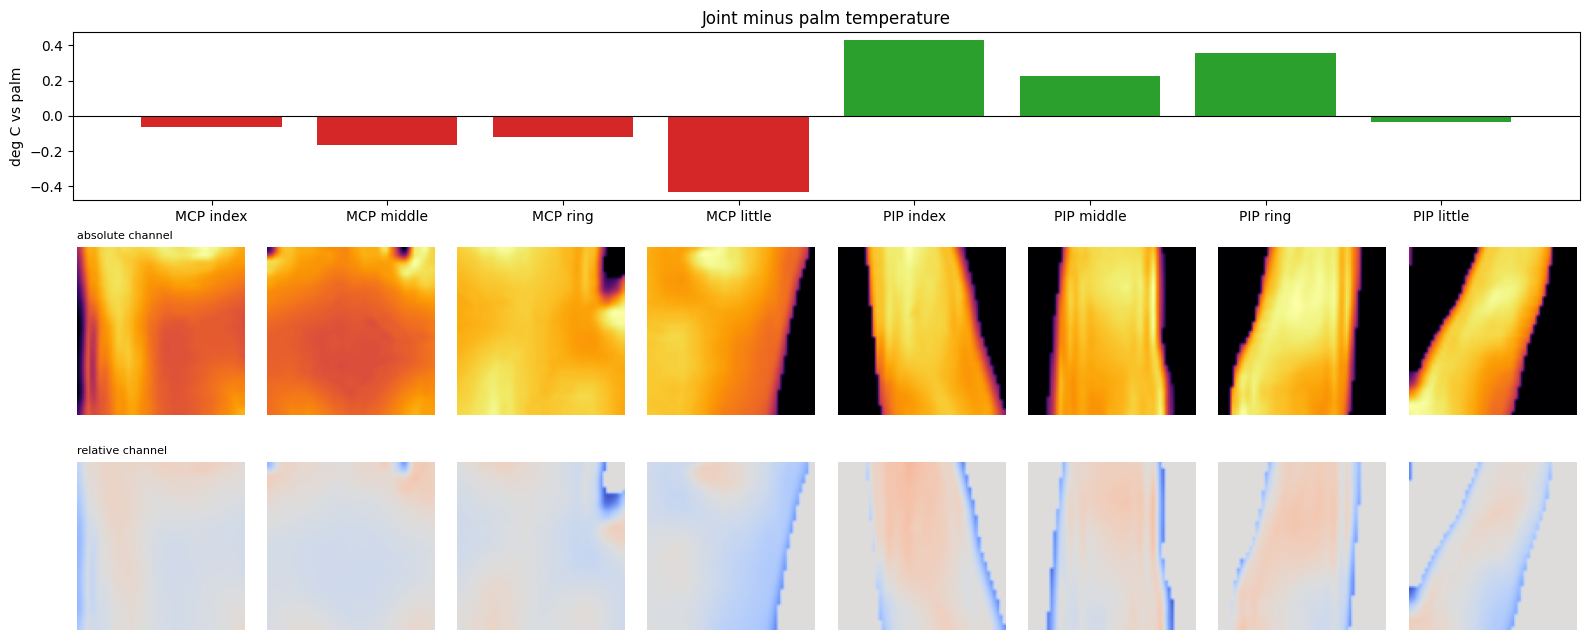

RGB branch (1, 8, 576) (0.93M params) | thermal branch (1, 8, 576) (0.93M params)


In [15]:
rgb_t = rgb_rois_to_tensor(rgb0g, pts)
th_t, d_t = thermal_rois_to_tensor(th0r, pts)

fig = plt.figure(figsize=(16, 6.5)); gs = fig.add_gridspec(3, 8)
axb = fig.add_subplot(gs[0, :])
axb.bar(JOINT_NAMES, d_t.squeeze(-1).numpy() * 2, color=["tab:red"] * 4 + ["tab:green"] * 4)
axb.axhline(0, color="k", lw=.8); axb.set(ylabel="deg C vs palm", title="Joint minus palm temperature")
for k in range(8):
    a1 = fig.add_subplot(gs[1, k]); a1.imshow(th_t[k, 0], cmap="inferno"); a1.axis("off")
    a2 = fig.add_subplot(gs[2, k]); a2.imshow(th_t[k, 1], cmap="coolwarm", vmin=-2, vmax=2); a2.axis("off")
    if k == 0:
        a1.set_title("absolute channel", fontsize=8, loc="left"); a2.set_title("relative channel", fontsize=8, loc="left")
plt.tight_layout(); plt.show()

nparams = lambda m: sum(p.numel() for p in m.parameters())
rgb_cnn, th_cnn = MobileBranch(3).to(DEVICE).eval(), MobileBranch(2).to(DEVICE).eval()
with torch.no_grad():
    fr, ft = rgb_cnn(rgb_t[None].to(DEVICE)), th_cnn(th_t[None].to(DEVICE))
print(f"RGB branch {tuple(fr.shape)} ({nparams(rgb_cnn) / 1e6:.2f}M params) | thermal branch {tuple(ft.shape)} ({nparams(th_cnn) / 1e6:.2f}M params)")

## Stage 06: Joint and cross-modal attention

**What it does:** attention lets the 8 joints compare with each other, and lets RGB and thermal look at each other.

**What to check:** the maps are nearly flat (about 0.125 each) because the model is not trained yet.

In [16]:
class JointCrossAttention(nn.Module):
    def __init__(self, d=128, heads=4, n_rois=N_ROIS, p=0.1):
        super().__init__()
        self.pos = nn.Parameter(torch.randn(1, n_rois, d) * 0.02)                # learned joint identity
        mha = lambda: nn.MultiheadAttention(d, heads, dropout=p, batch_first=True)
        self.self_r, self.self_t, self.r_from_t, self.t_from_r = mha(), mha(), mha(), mha()
        self.norm = nn.ModuleList([nn.LayerNorm(d) for _ in range(4)])

    def forward(self, r, t, return_weights=False):                               # r, t: (batch, 8, d)
        r, t = r + self.pos, t + self.pos
        a, w_sr = self.self_r(r, r, r);          r = self.norm[0](r + a)         # joints attend to joints (RGB)
        a, w_st = self.self_t(t, t, t);          t = self.norm[1](t + a)         # joints attend to joints (thermal)
        a, w_rt = self.r_from_t(r, t, t);        r2 = self.norm[2](r + a)        # RGB asks thermal
        a, w_tr = self.t_from_r(t, r, r);        t2 = self.norm[3](t + a)        # thermal asks RGB
        if return_weights:
            return r2, t2, {"self_r": w_sr, "self_t": w_st, "r_from_t": w_rt, "t_from_r": w_tr}
        return r2, t2

tokens (1, 8, 128) -> (1, 8, 128) | attention rows sum to [1. 1. 1. 1. 1. 1. 1. 1.]
untrained model: near-uniform maps (1/8 = 0.125) are expected


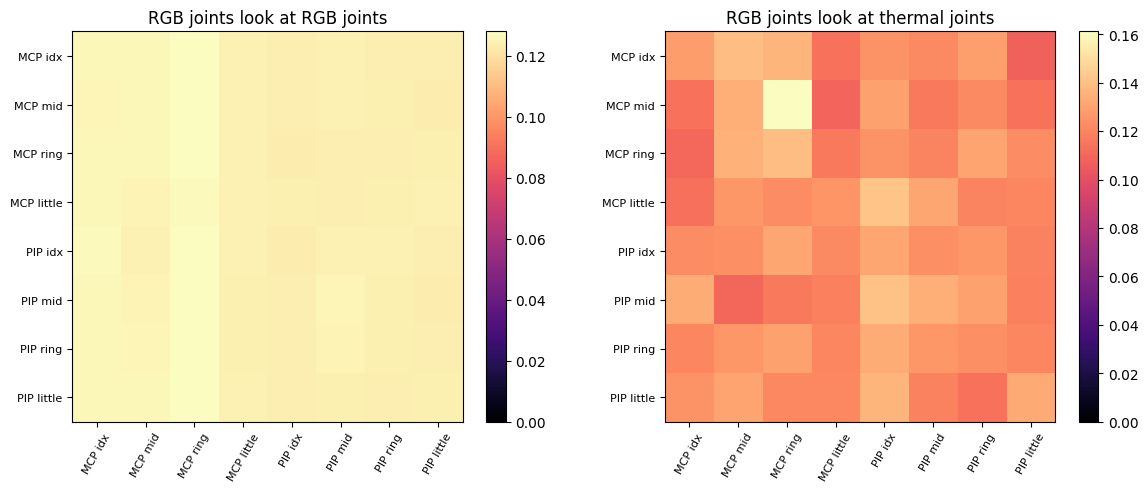

In [17]:
d = 128
proj_r, proj_t = nn.Linear(576, d).to(DEVICE), nn.Linear(577, d).to(DEVICE)
attn = JointCrossAttention(d).to(DEVICE).eval()
with torch.no_grad():
    r = proj_r(fr)
    t = proj_t(torch.cat([ft, d_t[None].to(DEVICE)], -1))
    r2, t2, w = attn(r, t, return_weights=True)
print("tokens", tuple(r.shape), "->", tuple(r2.shape), "| attention rows sum to", w["r_from_t"][0].sum(-1).cpu().numpy().round(2))
print("untrained model: near-uniform maps (1/8 = 0.125) are expected")

short = [n.replace("index", "idx").replace("middle", "mid") for n in JOINT_NAMES]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, key, title in zip(ax, ("self_r", "r_from_t"), ("RGB joints look at RGB joints", "RGB joints look at thermal joints")):
    im = a.imshow(w[key][0].cpu().numpy(), cmap="magma", vmin=0)
    a.set_xticks(range(8)); a.set_xticklabels(short, rotation=60, fontsize=8)
    a.set_yticks(range(8)); a.set_yticklabels(short, fontsize=8); a.set_title(title); plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

## Stage 07: Feature fusion

**What it does:** three ways to combine RGB and thermal: early, intermediate (attention plus a gate that decides how much to trust each), and decision. This is your ablation.

**What to check:** the output sizes, and a gate histogram around 0.5 before training.

In [18]:
class ModalityGate(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.g = nn.Linear(2 * d, d)
    def forward(self, r, t):                                   # (batch, d) each
        g = torch.sigmoid(self.g(torch.cat([r, t], -1)))
        return g * r + (1 - g) * t, g                          # g near 1 = trust RGB, near 0 = trust thermal

class Fusion(nn.Module):
    # "early": concatenate pooled features | "intermediate": attention + gate (proposed) | "decision": separate heads
    def __init__(self, d=128, mode="intermediate"):
        super().__init__()
        self.mode = mode
        self.attn = JointCrossAttention(d) if mode == "intermediate" else None
        self.gate = ModalityGate(d) if mode == "intermediate" else None
        self.mix = nn.Sequential(nn.Linear(2 * d, d), nn.ReLU()) if mode == "early" else None

    def forward(self, r, t):                                   # (batch, 8, d) each
        if self.mode == "intermediate":
            r, t = self.attn(r, t)
            return self.gate(r.mean(1), t.mean(1))
        r, t = r.mean(1), t.mean(1)
        if self.mode == "early":
            return self.mix(torch.cat([r, t], -1)), None
        return torch.cat([r, t], -1), None

early         output (1, 128) | gate: no
intermediate  output (1, 128) | gate: yes
decision      output (1, 256) | gate: no


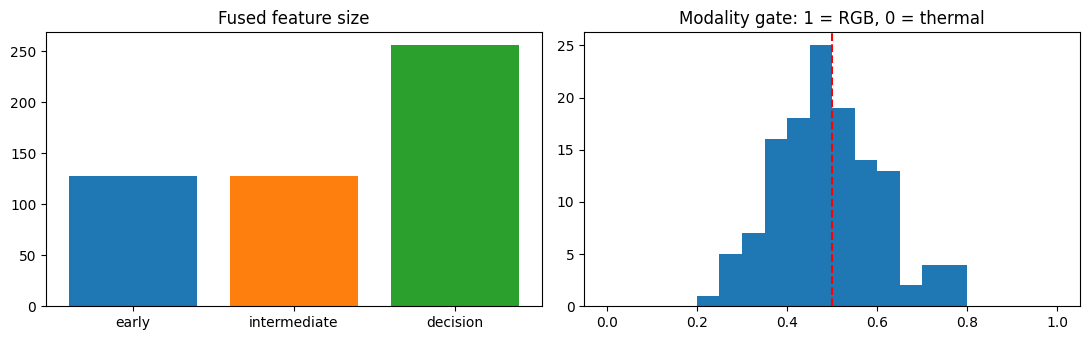

In [19]:
rows, gate_vals = [], None
for mode in ("early", "intermediate", "decision"):
    with torch.no_grad():
        z, g = Fusion(d, mode).to(DEVICE).eval()(r, t)
    rows.append((mode, z.shape[-1]))
    print(f"{mode:13s} output {tuple(z.shape)} | gate: {'yes' if g is not None else 'no'}")
    if g is not None:
        gate_vals = g[0].cpu().numpy()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar([m for m, _ in rows], [n for _, n in rows], color=["C0", "C1", "C2"]); ax[0].set_title("Fused feature size")
ax[1].hist(gate_vals, 20, range=(0, 1)); ax[1].axvline(0.5, color="r", ls="--")
ax[1].set_title("Modality gate: 1 = RGB, 0 = thermal")
plt.tight_layout(); plt.show()

## Stage 08: Classifier and evaluation

**What it does:** the classifier gives an RA score plus an uncertainty. The dataset has no RA labels, so it is tested on a stand-in task (static = 0, open-close = 1), with subjects split 70% train, 10% validation, 20% test.

1. **Data and split:** builds the dataset and keeps the test subjects out of the development data.
2. **Development:** cross-validation on the train and validation subjects only. Tune settings here.
3. **Final test:** train once and score the locked test subjects. Run it once only.

**What to check:** F1, AUROC and the per-subject AUROC on the test subjects. They say nothing about RA.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def make_head(d, p=0.3):
    return nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Dropout(p), nn.Linear(64, 1))

class DecisionHead(nn.Module):
    # decision-level fusion: one head per modality, logits averaged
    def __init__(self, d):
        super().__init__()
        self.hr, self.ht = make_head(d), make_head(d)
    def forward(self, z):
        r, t = z.chunk(2, -1)
        return (self.hr(r) + self.ht(t)) / 2

class RAModel(nn.Module):
    def __init__(self, d=128, fusion="intermediate", pretrained=True, freeze_backbone=False):
        super().__init__()
        self.rgb_cnn, self.th_cnn = MobileBranch(3, pretrained), MobileBranch(2, pretrained)
        self.proj_r = nn.Linear(MobileBranch.out_dim, d)
        self.proj_t = nn.Linear(MobileBranch.out_dim + 1, d)               # +1: joint-minus-palm temperature
        self.fusion = Fusion(d, fusion)
        self.head = DecisionHead(d) if fusion == "decision" else make_head(d)
        self.dt_head = nn.Linear(N_ROIS, 1)                                # direct path: 8 delta-T values -> logit
        nn.init.zeros_(self.dt_head.weight); nn.init.zeros_(self.dt_head.bias)
        self.freeze_backbone = freeze_backbone
        if freeze_backbone:                                                # small data: keep the pretrained CNNs fixed
            self.rgb_cnn.requires_grad_(False); self.th_cnn.requires_grad_(False)

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_backbone:
            self.rgb_cnn.eval(); self.th_cnn.eval()
        return self

    def embed(self, rgb, th, d_t):
        r = self.proj_r(self.rgb_cnn(rgb))
        t = self.proj_t(torch.cat([self.th_cnn(th), d_t], -1))
        return self.fusion(r, t)                                           # (features, gate)

    def forward(self, rgb, th, d_t):                                       # returns the logit
        z, _ = self.embed(rgb, th, d_t)
        return self.head(z).squeeze(-1) + self.dt_head(d_t.flatten(1)).squeeze(-1)

@torch.no_grad()
def predict_with_uncertainty(model, rgb, th, d_t, T=10):
    # score = mean over T dropout passes of the head; uncertainty = their spread
    model.eval()
    z, gate = model.embed(rgb, th, d_t)
    dt_term = model.dt_head(d_t.flatten(1)).squeeze(-1)
    model.head.train()
    p = torch.stack([torch.sigmoid(model.head(z).squeeze(-1) + dt_term) for _ in range(T)])
    model.head.eval()
    return p.mean(0), p.std(0), gate

def train_epoch(model, loader, opt):
    model.train(); total, n = 0.0, 0
    for rgb, th, d_t, y in loader:
        rgb, th, d_t, y = [a.to(DEVICE) for a in (rgb, th, d_t, y.float())]
        loss = F.binary_cross_entropy_with_logits(model(rgb, th, d_t), y)
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item() * len(y); n += len(y)
    return total / max(n, 1)

@torch.no_grad()
def predict_scores(model, loader):
    model.eval(); ys, ps = [], []
    for rgb, th, d_t, y in loader:
        ps.append(torch.sigmoid(model(rgb.to(DEVICE), th.to(DEVICE), d_t.to(DEVICE))).cpu().numpy()); ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)

def youden_threshold(y, p):
    # score threshold (predict positive when p >= threshold) that maximises TPR - FPR; choose it on validation data only
    fpr, tpr, thr = roc_curve(y, p)
    t = float(thr[int(np.argmax(tpr - fpr))])
    return t if np.isfinite(t) else 0.5

def split_by_subject(subjects, fracs=(0.7, 0.1, 0.2), seed=SEED):
    # train / validation / test split by SUBJECT: one subject's frames are never in two parts
    rng = np.random.RandomState(seed)
    names = [str(x) for x in rng.permutation(sorted(subjects))]
    n_tr, n_va = int(round(fracs[0] * len(names))), max(1, int(round(fracs[1] * len(names))))
    return {"train": names[:n_tr], "val": names[n_tr:n_tr + n_va], "test": names[n_tr + n_va:]}

def lr_baseline(F_tr, y_tr, F_te):
    # simple logistic-regression baseline the CNN has to beat
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(F_tr, y_tr).predict_proba(F_te)[:, 1]

def features(D):
    # the two baseline features: log sharpness and the 8 joint delta-T values
    return {"sharp": np.log(D["sharp"] + 1e-6)[:, None], "dt": D["dt"].squeeze(-1).numpy()}

def show_results(y, p, pred, g, p_dt, p_sharp, title):
    # y: true labels | p: CNN scores | pred: 0/1 predictions | g: subject of each frame | p_dt, p_sharp: baseline scores
    auc, f1 = roc_auc_score(y, p), f1_score(y, pred)
    print(f"\n{title}")
    print(f"AUROC {auc:.3f} | F1 {f1:.3f} | accuracy {accuracy_score(y, pred):.3f} | predicted-positive rate {pred.mean():.2f}"
          + ("   <-- collapsed classifier" if pred.mean() > 0.9 or pred.mean() < 0.1 else ""))
    print(f"baseline AUROC: delta-T only {roc_auc_score(y, p_dt):.3f} | sharpness only {roc_auc_score(y, p_sharp):.3f}")
    print("AUROC per subject:", {str(s): round(roc_auc_score(y[g == s], p[g == s]), 2) for s in np.unique(g)})
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for name, pp in (("CNN", p), ("delta-T only", p_dt), ("sharpness only", p_sharp)):
        fpr, tpr, _ = roc_curve(y, pp); ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y, pp):.2f})")
    ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].legend(); ax[0].set_title("ROC")
    cm = confusion_matrix(y, pred, labels=[0, 1]); ax[1].imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): ax[1].text(j, i, v, ha="center", va="center", color="w" if v > cm.max() / 2 else "k", fontsize=14)
    ax[1].set(xticks=[0, 1], yticks=[0, 1], xlabel="predicted", ylabel="true", title="Confusion matrix")
    ax[2].bar(["F1", "AUROC"], [f1, auc], color=["C0", "C1"])
    ax[2].plot([-.4, .4], [TARGET_F1] * 2, "r--"); ax[2].plot([.6, 1.4], [TARGET_AUROC] * 2, "r--")
    ax[2].set(ylim=(0, 1.05), title="Stand-in result vs RA targets (red)")
    plt.tight_layout(); plt.show()
    return auc, f1

### Data and subject split (70% train / 10% validation / 20% test)

In [21]:
# The dataset has no RA labels, so the whole method is tested on a STAND-IN task: static (0) vs open-close (1).
from torch.utils.data import DataLoader, TensorDataset

N_PER_CLASS = 12                                         # frames per subject per task
CACHE = Path("ra_standin_cache_v3.pt")                   # delete this file after changing Stages 02-05

def collect_subject(subject, step=15):
    recs = {0: list(iter_pairs(subject, HAND, "static", step=step)), 1: list(iter_pairs(subject, HAND, "open_close", step=step))}
    M, _ = calibrate_registration(recs[0] + recs[1], verbose=False)                # one registration per subject
    out = {k: [] for k in ("rgb", "th", "dt", "y", "sharp")}
    why = Counter()
    for label in (0, 1):
        sharp = [quality_check(r, t)["sharpness"] for _, r, t in recs[label]]
        min_sharp = calibrate_min_sharp(sharp)
        kept = []
        for (_, rgb, th), s in zip(recs[label], sharp):
            sample, reasons, _, _ = build_sample(rgb, th, M, min_sharp)
            if sample is None: why.update(reasons)
            else: kept.append((sample, s))
        if len(kept) < 4:
            print(f"  {subject}: skipped, only {len(kept)} usable frames for label {label} | {dict(why)}")
            return None
        for k in np.unique(np.linspace(0, len(kept) - 1, N_PER_CLASS).astype(int)):      # evenly spaced frames
            (a, b, c), s = kept[k]
            for key, v in zip(("rgb", "th", "dt", "y", "sharp"), (a, b, c, label, s)): out[key].append(v)
    print(f"  {subject}: {len(out['y'])} samples | registration {'ok' if M is not None else 'FAILED'} | rejected: {dict(why)}")
    return {"rgb": torch.stack(out["rgb"]), "th": torch.stack(out["th"]), "dt": torch.stack(out["dt"]),
            "y": torch.tensor(out["y"]), "sharp": torch.tensor(out["sharp"], dtype=torch.float32)}

if CACHE.exists():
    data = torch.load(CACHE); print("loaded", CACHE)
else:
    data = {s: collect_subject(s) for s in SUBJECTS}
    data = {s: v for s, v in data.items() if v is not None}
    torch.save(data, CACHE)

subs = sorted(data)
assert len(subs) >= 8, "too few usable subjects: read the lines above"
split = split_by_subject(subs)
for part, names in split.items():
    print(f"{part:5s} ({len(names)} subjects): {names}")
assert not (set(split["train"]) & set(split["val"]) or set(split["train"]) & set(split["test"]) or set(split["val"]) & set(split["test"]))

def stack(names):
    # all frames of the given subjects as one dataset; "g" records which subject each frame belongs to
    return {k: torch.cat([data[s][k] for s in names]) for k in ("rgb", "th", "dt", "y")} | {
        "sharp": torch.cat([data[s]["sharp"] for s in names]).numpy(),
        "g": np.concatenate([[s] * len(data[s]["y"]) for s in names])}

DEV = stack(split["train"] + split["val"])               # development data: the test subjects are NOT in here
print(f"development set: {len(DEV['y'])} frames from {len(split['train']) + len(split['val'])} subjects "
      f"| test subjects are kept aside until the last cell")

def make_loader(D, idx, shuffle):
    idx = torch.as_tensor(idx)
    return DataLoader(TensorDataset(D["rgb"][idx], D["th"][idx], D["dt"][idx], D["y"][idx]), batch_size=8, shuffle=shuffle)

def fit_cnn(D, tr_idx, va_idx, epochs=15):
    model = RAModel(freeze_backbone=True).to(DEVICE)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=3e-4, weight_decay=1e-2)
    tr_loader, va_loader = make_loader(D, tr_idx, True), make_loader(D, va_idx, False)
    best, best_state, history = -1.0, None, []
    for _ in range(epochs):
        history.append(train_epoch(model, tr_loader, opt))
        yv, pv = predict_scores(model, va_loader)
        auc = roc_auc_score(yv, pv) if len(set(yv)) > 1 else 0.5
        if auc > best:                                              # keep the epoch that is best on validation subjects
            best, best_state = auc, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, history

loaded ra_standin_cache_v3.pt
train (11 subjects): ['S10', 'S15', 'S2', 'S3', 'S7', 'S13', 'S11', 'S8', 'S4', 'S16', 'S9']
val   (2 subjects): ['S5', 'S12']
test  (3 subjects): ['S1', 'S14', 'S6']
development set: 312 frames from 13 subjects | test subjects are kept aside until the last cell


### Development (tune settings here, never on the test subjects)

fold 0: test subjects [np.str_('S12'), np.str_('S3'), np.str_('S9')] | AUROC CNN 0.81 | delta-T only 0.74 | sharpness only 0.48 | threshold 0.985
fold 1: test subjects [np.str_('S11'), np.str_('S2'), np.str_('S8')] | AUROC CNN 0.88 | delta-T only 0.50 | sharpness only 0.46 | threshold 0.920
fold 2: test subjects [np.str_('S10'), np.str_('S16'), np.str_('S7')] | AUROC CNN 0.92 | delta-T only 0.55 | sharpness only 0.37 | threshold 0.998
fold 3: test subjects [np.str_('S15'), np.str_('S5')] | AUROC CNN 0.73 | delta-T only 0.82 | sharpness only 0.48 | threshold 0.677
fold 4: test subjects [np.str_('S13'), np.str_('S4')] | AUROC CNN 0.80 | delta-T only 0.74 | sharpness only 0.49 | threshold 0.694
mean AUROC over folds 0.827 +/- 0.067

DEVELOPMENT (subject-wise CV, pooled over folds)
AUROC 0.744 | F1 0.767 | accuracy 0.782 | predicted-positive rate 0.44
baseline AUROC: delta-T only 0.623 | sharpness only 0.435
AUROC per subject: {'S10': np.float64(0.81), 'S11': np.float64(0.94), 'S12': np.fl

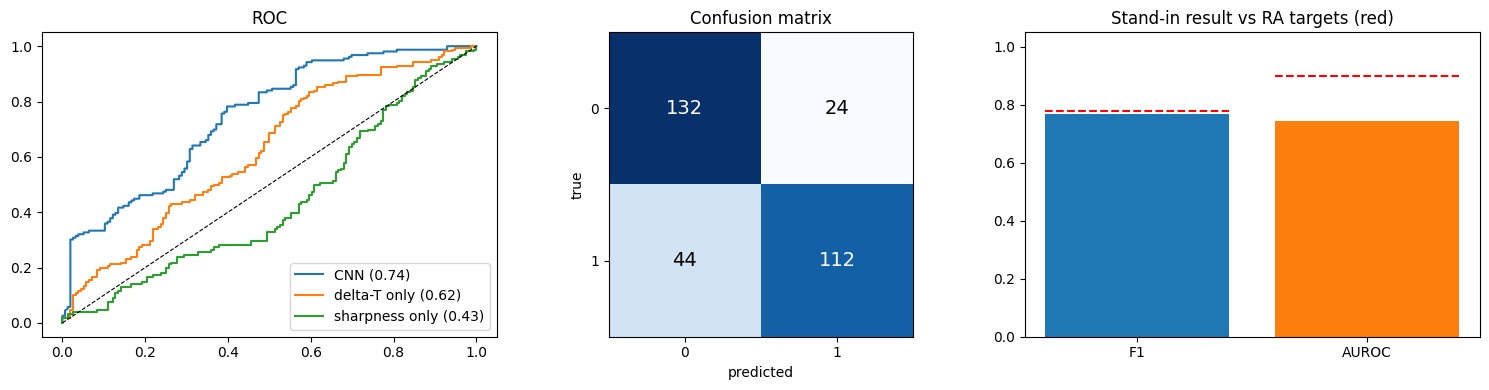

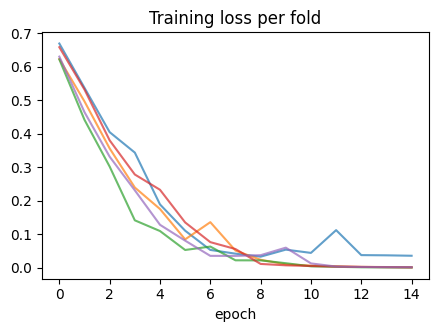

In [22]:
# Subject-wise 5-fold CV inside the development subjects only. Use it to choose epochs, learning rate, thresholds, etc.
FD = features(DEV)
rng = np.random.RandomState(SEED)
y_all, p_all, pred_all, g_all, bl_sharp, bl_dt, histories, fold_auc = [], [], [], [], [], [], [], []
for fold, (tr_all, te_idx) in enumerate(GroupKFold(n_splits=5).split(np.zeros(len(DEV["y"])), groups=DEV["g"])):
    va_subs = list(rng.choice(sorted(set(DEV["g"][tr_all])), 2, replace=False))        # 2 validation subjects
    va_idx = np.where(np.isin(DEV["g"], va_subs))[0]
    tr_idx = np.array([i for i in tr_all if DEV["g"][i] not in va_subs])
    model, hist = fit_cnn(DEV, tr_idx, va_idx); histories.append(hist)
    thr = youden_threshold(*predict_scores(model, make_loader(DEV, va_idx, False)))
    yt, pt = predict_scores(model, make_loader(DEV, te_idx, False))
    p_dt = lr_baseline(FD["dt"][tr_all], DEV["y"][tr_all].numpy(), FD["dt"][te_idx])
    p_sharp = lr_baseline(FD["sharp"][tr_all], DEV["y"][tr_all].numpy(), FD["sharp"][te_idx])
    y_all.append(yt); p_all.append(pt); pred_all.append(pt >= thr); g_all.append(DEV["g"][te_idx]); bl_dt.append(p_dt); bl_sharp.append(p_sharp)
    fold_auc.append(roc_auc_score(yt, pt))
    print(f"fold {fold}: test subjects {sorted(set(DEV['g'][te_idx]))} | AUROC CNN {fold_auc[-1]:.2f} | "
          f"delta-T only {roc_auc_score(yt, p_dt):.2f} | sharpness only {roc_auc_score(yt, p_sharp):.2f} | threshold {thr:.3f}")

print(f"mean AUROC over folds {np.mean(fold_auc):.3f} +/- {np.std(fold_auc):.3f}")
show_results(np.concatenate(y_all), np.concatenate(p_all), np.concatenate(pred_all).astype(int), np.concatenate(g_all),
             np.concatenate(bl_dt), np.concatenate(bl_sharp), "DEVELOPMENT (subject-wise CV, pooled over folds)")
plt.figure(figsize=(5, 3.2)); [plt.plot(h, alpha=.7) for h in histories]; plt.title("Training loss per fold"); plt.xlabel("epoch"); plt.show()

### Final test (run once, after all settings are fixed)


FINAL TEST on subjects ['S1', 'S14', 'S6'] (threshold 0.996 chosen on the validation subjects)
AUROC 0.944 | F1 0.780 | accuracy 0.819 | predicted-positive rate 0.32
baseline AUROC: delta-T only 0.721 | sharpness only 0.636
AUROC per subject: {'S1': np.float64(0.93), 'S14': np.float64(0.94), 'S6': np.float64(0.98)}


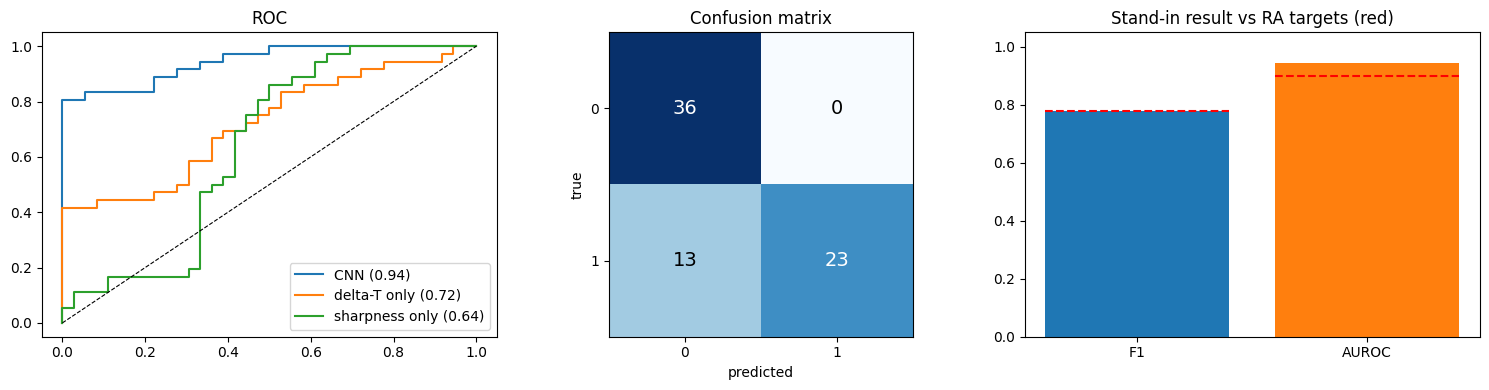

In [23]:
# Train on the train subjects, stop early and pick the threshold on the validation subjects,
# then score the test subjects, which no earlier step has used.
if globals().get("FINAL_DONE"):
    print("WARNING: the test subjects were already used. Changing settings and re-running makes this result unreliable.")
FINAL_DONE = True

TEST = stack(split["test"])
FD, FT = features(DEV), features(TEST)
tr_idx = np.where(np.isin(DEV["g"], split["train"]))[0]
va_idx = np.where(np.isin(DEV["g"], split["val"]))[0]
model, hist = fit_cnn(DEV, tr_idx, va_idx)
thr = youden_threshold(*predict_scores(model, make_loader(DEV, va_idx, False)))
yt, pt = predict_scores(model, make_loader(TEST, np.arange(len(TEST["y"])), False))
p_dt = lr_baseline(FD["dt"], DEV["y"].numpy(), FT["dt"])
p_sharp = lr_baseline(FD["sharp"], DEV["y"].numpy(), FT["sharp"])
show_results(yt, pt, (pt >= thr).astype(int), TEST["g"], p_dt, p_sharp,
             f"FINAL TEST on subjects {split['test']} (threshold {thr:.3f} chosen on the validation subjects)")
last_model = model

## Stage 09: Deploy and benchmark

**What it does:** counts parameters, times the model, and exports it to ONNX for the Jetson.

**What to check:** under 5M parameters and under 50 ms. Repeat the timing on the Jetson.

In [24]:
count_params = lambda m: sum(p.numel() for p in m.parameters())

@torch.no_grad()
def benchmark(model, runs=100, warmup=20):
    model.eval().to(DEVICE)
    args = (torch.randn(1, N_ROIS, 3, ROI_SIZE, ROI_SIZE, device=DEVICE),
            torch.randn(1, N_ROIS, 2, ROI_SIZE, ROI_SIZE, device=DEVICE),
            torch.randn(1, N_ROIS, 1, device=DEVICE))
    for _ in range(warmup): model(*args)
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs): model(*args)
    if DEVICE == "cuda": torch.cuda.synchronize()
    return count_params(model), (time.perf_counter() - t0) / runs * 1000

def export_onnx(model, path="ra_model.onnx"):
    model.eval().cpu()
    args = (torch.randn(1, N_ROIS, 3, ROI_SIZE, ROI_SIZE), torch.randn(1, N_ROIS, 2, ROI_SIZE, ROI_SIZE), torch.randn(1, N_ROIS, 1))
    kw = dict(opset_version=17, input_names=["rgb_rois", "thermal_rois", "delta_t"], output_names=["logit"])
    try:
        torch.onnx.export(model, args, path, dynamo=False, **kw)
    except TypeError:
        torch.onnx.export(model, args, path, **kw)

parameters 2.31M (target <= 5M) | latency 13.1 ms on cuda (target <= 50 ms; repeat on the Jetson)


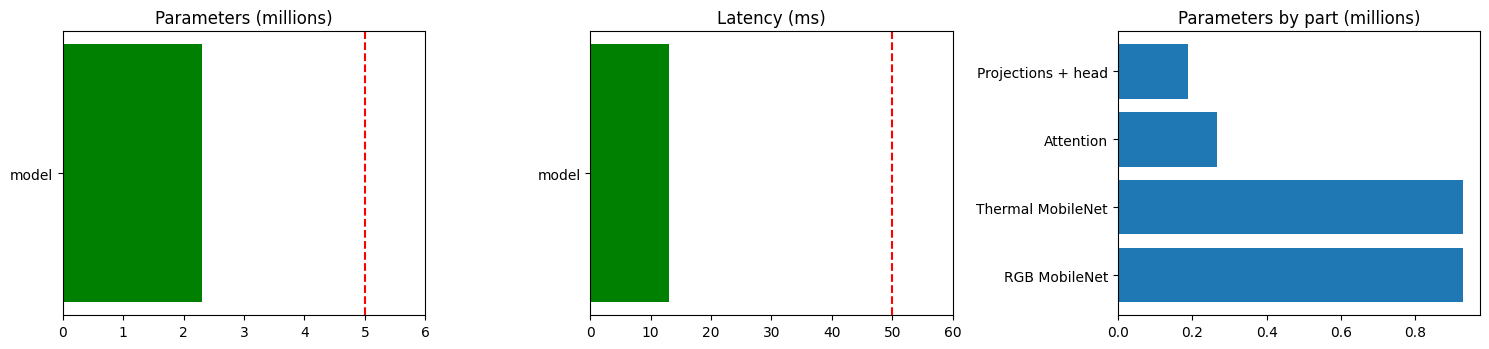

/tmp/ipykernel_915/4202881884.py:21: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, args, path, dynamo=False, **kw)


saved ra_model.onnx (9.2 MB)


In [25]:
m_eval = RAModel(pretrained=False)
n_params, ms = benchmark(m_eval)
parts = {"RGB MobileNet": m_eval.rgb_cnn, "Thermal MobileNet": m_eval.th_cnn, "Attention": m_eval.fusion.attn,
         "Projections + head": nn.ModuleList([m_eval.proj_r, m_eval.proj_t, m_eval.head, m_eval.dt_head, m_eval.fusion.gate])}
print(f"parameters {n_params / 1e6:.2f}M (target <= 5M) | latency {ms:.1f} ms on {DEVICE} (target <= 50 ms; repeat on the Jetson)")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].barh(["model"], [n_params / 1e6], color="g" if n_params <= 5e6 else "r"); ax[0].axvline(5, color="r", ls="--"); ax[0].set(xlim=(0, 6), title="Parameters (millions)")
ax[1].barh(["model"], [ms], color="g" if ms <= 50 else "r"); ax[1].axvline(50, color="r", ls="--"); ax[1].set(xlim=(0, max(60, ms * 1.2)), title="Latency (ms)")
ax[2].barh(list(parts), [count_params(m) / 1e6 for m in parts.values()]); ax[2].set_title("Parameters by part (millions)")
plt.tight_layout(); plt.show()

export_onnx(m_eval)
print(f"saved ra_model.onnx ({os.path.getsize('ra_model.onnx') / 1e6:.1f} MB)")

## End-to-end demo

**What it does:** runs the whole pipeline on one recording and shows a score on each accepted frame. The score means open-close, not RA, because training used the stand-in task.

registration: scale 0.827 | rot 0.3 deg | shift (52, 82) px | landmark error 34% -> 2% of hand length
accepted 8 frames | rejected {'blurry': 4, 'low thermal contrast / no hand': 4}


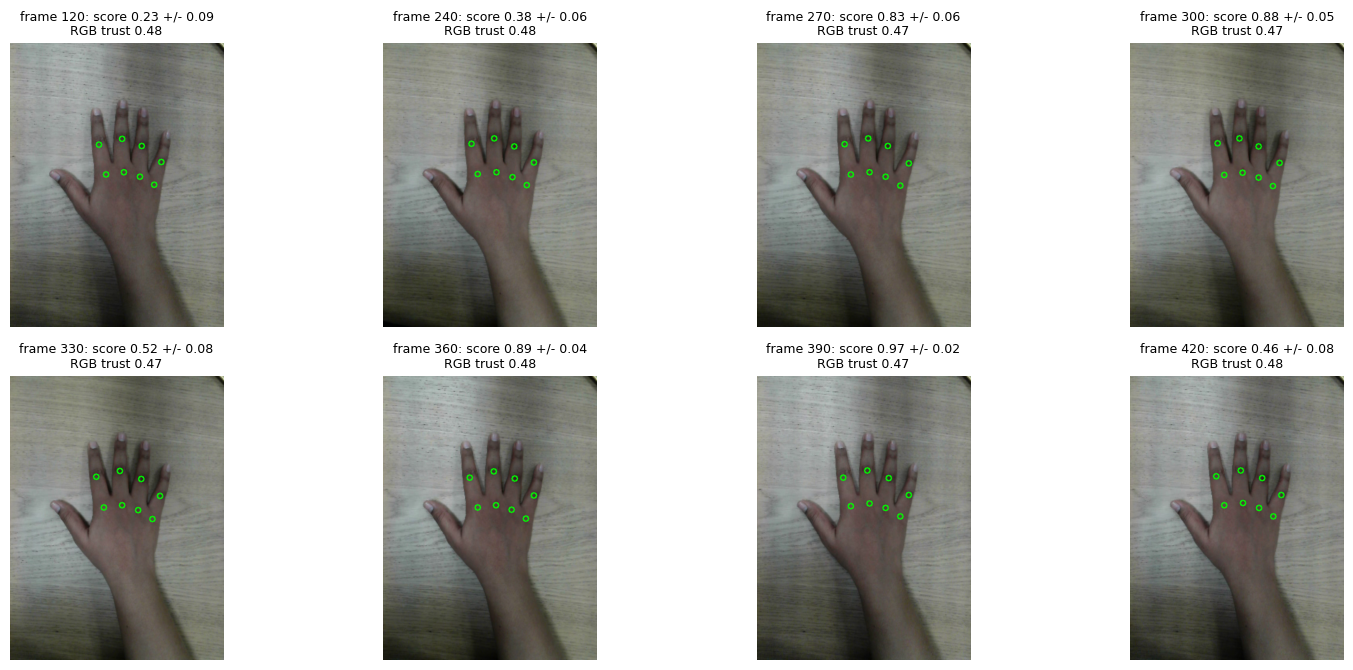

In [26]:
def run_demo(subject=SUBJ, hand=HAND, task=TASK, model=None, step=30, max_show=8):
    model = (model or RAModel(pretrained=False)).to(DEVICE).eval()
    frames = list(iter_pairs(subject, hand, task, step=step))
    M, _ = calibrate_registration(frames)
    min_sharp = calibrate_min_sharp([quality_check(r, t)["sharpness"] for _, r, t in frames])
    shown, rejected = [], Counter()
    for i, rgb, thermal in frames:
        sample, why, pts, rgb_p = build_sample(rgb, thermal, M, min_sharp)
        if sample is None:
            rejected.update(why); continue
        rgb_t, th_t, d_t = (x[None].to(DEVICE) for x in sample)
        score, unc, gate = predict_with_uncertainty(model, rgb_t, th_t, d_t)
        shown.append((i, rgb_p.copy(), pts, score.item(), unc.item(), gate.mean().item()))
        if len(shown) >= max_show: break
    print(f"accepted {len(shown)} frames | rejected {dict(rejected)}")
    fig, axs = plt.subplots(max(1, int(np.ceil(len(shown) / 4))), 4, figsize=(16, 3.4 * max(1, int(np.ceil(len(shown) / 4)))))
    axs = np.atleast_1d(axs).ravel()
    for a in axs: a.axis("off")
    for a, (i, im, pts, sc, un, g) in zip(axs, shown):
        for j in JOINTS: cv2.circle(im, (int(pts[j][0]), int(pts[j][1])), 6, (0, 255, 0), 2)
        a.imshow(bgr2rgb(im)); a.set_title(f"frame {i}: score {sc:.2f} +/- {un:.2f}\nRGB trust {g:.2f}", fontsize=9)
    plt.tight_layout(); plt.show()

run_demo(model=last_model)       # last_model: trained on the stand-in task, so the score means "open-close", not RA